<a href="https://colab.research.google.com/github/olonok69/SSL_pathology_demo/blob/main/notebooks/06_anomaly_detection_on_embeddings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 06 · Anomaly detection on embeddings

**Goal.** Fit a head on normal tiles only, then ask whether a new backbone helps when that head stays the same.

**What you will see.** Three heads (kNN distance, shrinkage Mahalanobis, Isolation Forest) on Task A: non-tumour tissue is normal, colorectal adenocarcinoma is the anomaly, background is held out and reported as a flag rate. Task B (normal lymph node vs metastasis) runs only if notebook 03 cached PatchCamelyon features. Then the false-positive gallery: normal tiles the head ranked as most abnormal.

**Runtime.** About 15 minutes on cached features.

**Talking point.** Slides 22–27. The decision rule is fixed in this cell, before any score is computed.

## Decision rule (fixed before the numbers)

A backbone is clearly better if its AUROC 95% CI does not overlap the next-best backbone's CI on **both** Task A and Task B, for the kNN-distance head. Same tiles, same head, same seeds.

If Task B is not in the cache, the rule cannot name a cross-task winner. Overlapping intervals mean "not clearly better", even when the point estimate is higher. The threshold for sensitivity and false positives is the 99th percentile of scores on held-out normal tiles, not a threshold tuned on tumours.


In [1]:
import os
import subprocess
from pathlib import Path
repo = Path("/content/SSL_pathology_demo")
if not (repo / "pyproject.toml").exists():
    subprocess.check_call([
        "git", "clone", "--depth", "1",
        "https://github.com/olonok69/SSL_pathology_demo.git",
        str(repo),
    ])
os.chdir(repo)

In [2]:
MODE = "fast"  # "fast" or "full"

import os
import sys
from pathlib import Path

def _find_repo() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "pyproject.toml").exists() and (candidate / "src" / "ssl_demo").is_dir():
            return candidate
    raise FileNotFoundError(
        "Launch this notebook from the ssl-pathology-demo repository "
        "(the folder that contains pyproject.toml)."
    )

REPO = _find_repo()
os.chdir(REPO)
src = str(REPO / "src")
if src not in sys.path:
    sys.path.insert(0, src)

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    import subprocess
    # pyproject.toml does not pin torch, so a Colab CUDA wheel stays installed.
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-e", str(REPO)])

from ssl_demo.config import SEED, cache_root

CACHE = cache_root()
print(f"MODE={MODE}  SEED={SEED}")
print(f"cache: {CACHE}")


Mounted at /content/drive
MODE=fast  SEED=42
cache: /content/drive/MyDrive/ssl-demo


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ssl_demo.anomaly import (
    DECISION_RULE,
    anomaly_test_set,
    decide_backbone,
    highest_scoring,
    normal_pool,
    run_anomaly_task,
)
from ssl_demo.backbones import PHASE1_BACKBONES
from ssl_demo.config import ANOMALY_CSV, save_results_csv
from ssl_demo.data import (
    BACKGROUND_ID,
    CLASS_NAMES,
    NORMAL_IDS,
    PCAM_NORMAL_ID,
    PCAM_TUMOUR_ID,
    TUMOUR_ID,
    feature_dir,
    prepare_pathmnist,
)
from ssl_demo.extract import is_cached, load_cached

print(DECISION_RULE)
print()
print("Task A normal classes:", [CLASS_NAMES[i] for i in NORMAL_IDS])
print("Task A anomaly:", CLASS_NAMES[TUMOUR_ID])
print("Held out of the fit:", CLASS_NAMES[BACKGROUND_ID])


A backbone is clearly better if its AUROC 95% CI does not overlap the next-best backbone's CI on both Task A and Task B, for the kNN-distance head. Same tiles, same head, same seeds. The rule is fixed before looking at the numbers. If Task B features are not cached, the rule cannot declare a cross-task winner.

Task A normal classes: ['adipose', 'debris', 'lymphocytes', 'mucus', 'smooth muscle', 'normal colon mucosa', 'cancer-associated stroma']
Task A anomaly: colorectal adenocarcinoma epithelium
Held out of the fit: background


In [4]:
def _require(dataset: str) -> None:
    for name in PHASE1_BACKBONES:
        for split in ("train", "test"):
            if not is_cached(feature_dir(CACHE, dataset, split, MODE), name):
                raise FileNotFoundError(
                    f"Missing {dataset} {split} features for {name}. Run notebook 03 first."
                )

_require("pathmnist")
sources = prepare_pathmnist(mode=MODE, cache=CACHE, seed=SEED, size=224, download=True)
test_images = sources["test"]

frames = []
runs = {}
for name in PHASE1_BACKBONES:
    train = load_cached(feature_dir(CACHE, "pathmnist", "train", MODE), name)
    test = load_cached(feature_dir(CACHE, "pathmnist", "test", MODE), name)
    pool, _positions = normal_pool(train.features, train.labels, NORMAL_IDS)
    background = train.features[train.labels == BACKGROUND_ID]
    eval_x, eval_y, eval_pos = anomaly_test_set(
        test.features, test.labels, NORMAL_IDS, (TUMOUR_ID,)
    )
    run = run_anomaly_task(
        pool,
        eval_x,
        eval_y,
        backbone=name,
        task="task_a",
        dataset="pathmnist",
        n_boot=1000,
        background_features=background,
        test_positions=test.index[eval_pos],
    )
    frames.append(run.table)
    runs[name] = run
    print(f"{name}: fit pool {len(pool)}, test rows {len(eval_y)}, tumour {int(eval_y.sum())}")


random_resnet50: fit pool 7511, test rows 1764, tumour 344
sup_resnet50_in1k: fit pool 7511, test rows 1764, tumour 344
dinov2_vits14: fit pool 7511, test rows 1764, tumour 344


In [5]:
pcam_ready = all(
    is_cached(feature_dir(CACHE, "pcam", split, MODE), name)
    for name in PHASE1_BACKBONES
    for split in ("train", "test")
)
if pcam_ready:
    for name in PHASE1_BACKBONES:
        train = load_cached(feature_dir(CACHE, "pcam", "train", MODE), name)
        test = load_cached(feature_dir(CACHE, "pcam", "test", MODE), name)
        pool, _positions = normal_pool(train.features, train.labels, (PCAM_NORMAL_ID,))
        eval_x, eval_y, eval_pos = anomaly_test_set(
            test.features, test.labels, (PCAM_NORMAL_ID,), (PCAM_TUMOUR_ID,)
        )
        run = run_anomaly_task(
            pool,
            eval_x,
            eval_y,
            backbone=name,
            task="task_b",
            dataset="pcam",
            n_boot=1000,
            test_positions=test.index[eval_pos],
        )
        frames.append(run.table)
        print(f"task B {name}: fit pool {len(pool)}, test rows {len(eval_y)}")
else:
    print(
        "Task B skipped: no PatchCamelyon feature cache. "
        "The two-task rule cannot declare a winner from Task A alone."
    )

results = pd.concat(frames, ignore_index=True)
paths = save_results_csv(results, ANOMALY_CSV, CACHE)
print("wrote", paths[0])


task B random_resnet50: fit pool 2500, test rows 2000
task B sup_resnet50_in1k: fit pool 2500, test rows 2000
task B dinov2_vits14: fit pool 2500, test rows 2000
wrote /content/drive/MyDrive/ssl-demo/results/anomaly.csv


In [6]:
auroc = results[(results["metric"] == "auroc") & (~results["task"].str.endswith("background"))]
pivot = auroc.pivot_table(index="backbone", columns=["task", "head"], values="value")
print(pivot.to_string())

decision = decide_backbone(results)
print(decision.reason)
print("winner:", decision.winner)


task                        task_a                                    task_b                         
head              isolation_forest knn_distance mahalanobis isolation_forest knn_distance mahalanobis
backbone                                                                                             
dinov2_vits14             0.439867     0.674869    0.601605         0.476755     0.512384    0.507649
random_resnet50           0.861544     0.898002    0.887705         0.649658     0.716268    0.690864
sup_resnet50_in1k         0.407491     0.687793    0.617945         0.479818     0.572409    0.551605
random_resnet50 is clearly better on both tasks. task_a: random_resnet50 AUROC 0.898 [0.881, 0.914] is clear of sup_resnet50_in1k [0.660, 0.713]. task_b: random_resnet50 AUROC 0.716 [0.694, 0.737] is clear of sup_resnet50_in1k [0.548, 0.598].
winner: random_resnet50


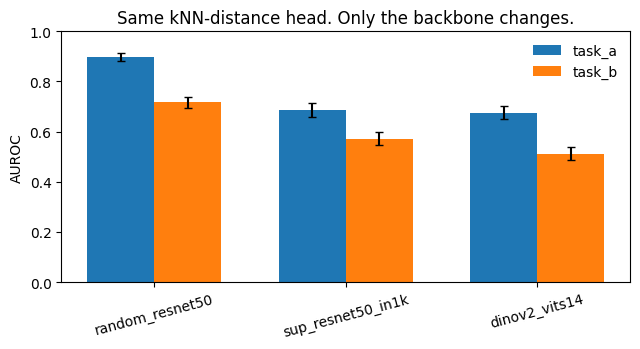

In [7]:
# Backbone-swap view: kNN-distance AUROC, the head named in the rule.
block = auroc[auroc["head"] == "knn_distance"]
tasks = list(block["task"].unique())
fig, ax = plt.subplots(figsize=(6.5, 3.6))
x = np.arange(len(PHASE1_BACKBONES))
width = 0.35 if len(tasks) > 1 else 0.5
for i, task in enumerate(tasks):
    chunk = block[block["task"] == task].set_index("backbone").loc[list(PHASE1_BACKBONES)]
    offset = (i - (len(tasks) - 1) / 2) * width
    ax.bar(x + offset, chunk["value"], width=width, label=task)
    low = np.clip(chunk["value"] - chunk["ci_low"], 0, None)
    high = np.clip(chunk["ci_high"] - chunk["value"], 0, None)
    ax.errorbar(
        x + offset,
        chunk["value"],
        yerr=[low, high],
        fmt="none",
        ecolor="black",
        capsize=3,
    )
ax.set_xticks(x)
ax.set_xticklabels(PHASE1_BACKBONES, rotation=15)
ax.set_ylim(0, 1)
ax.set_ylabel("AUROC")
ax.set_title("Same kNN-distance head. Only the backbone changes.")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


## False-positive gallery

These are test tiles from **non-tumour** classes that the kNN-distance head scored as most abnormal. Debris, folds and edge tiles often land here. That is normal variation and artefact, and it is why a high score is not yet a tumour call.


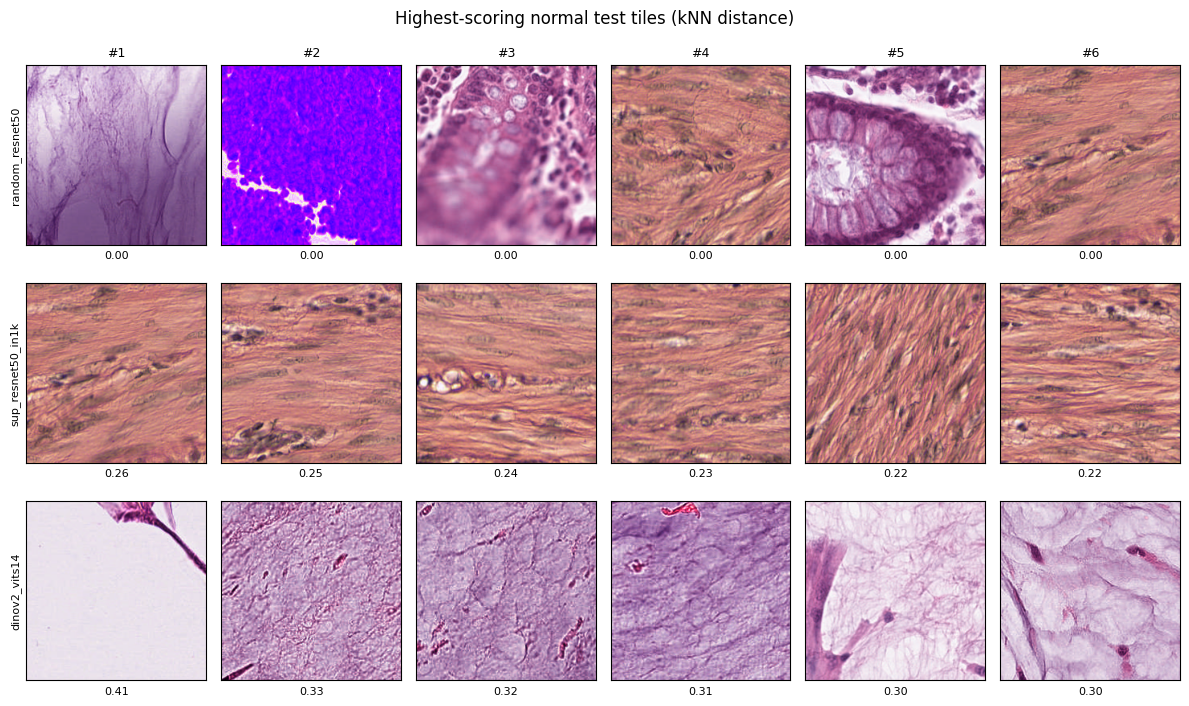

In [8]:
fig, axes = plt.subplots(len(PHASE1_BACKBONES), 6, figsize=(12, 2.4 * len(PHASE1_BACKBONES)))
for row, name in enumerate(PHASE1_BACKBONES):
    run = runs[name]
    normal = run.test_y == 0
    _local, scores = highest_scoring(
        np.flatnonzero(normal),
        run.scores["knn_distance"][normal],
        k=6,
    )
    for col, position in enumerate(_local):
        source_index = int(run.test_positions[int(position)])
        axes[row, col].imshow(test_images.image(source_index))
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
        if row == 0:
            axes[row, col].set_title(f"#{col + 1}", fontsize=9)
        if col == 0:
            axes[row, col].set_ylabel(name, fontsize=8)
        axes[row, col].set_xlabel(f"{scores[col]:.2f}", fontsize=8)
fig.suptitle("Highest-scoring normal test tiles (kNN distance)")
fig.tight_layout()
plt.show()


## What we learned

- The three heads see only normal features at fit time. Tumour tiles are used when we score, not when we choose the threshold.
- Swapping the backbone and keeping the head is the whole comparison. The rule above either names a winner on both tasks or it refuses to.
- The gallery is the artefact story: a high score on debris or a fold is a false positive, and background was kept out of the AUROC for the same reason.

Table: `results/anomaly.csv`.
